# python notebook for Make Your Own Neural Network
## code for a 3 layer neural network, and code for learning the MNIST dataset

In [193]:
# scipy.special for the sigmoid function expit()
import scipy.special

import numpy as np
import matplotlib.pyplot as plt

In [194]:
class NeuralNetwork:
    #initialize the network
    def __init__(self, input_nodes, hidden_nodes, output_nodes, learning_rate):
        #set number of nodes in each input,output and hidden nodes
        self.innodes = input_nodes
        self.hnodes = hidden_nodes
        self.outnodes = output_nodes

        #weight matrics wih(input--hidden) and who(hidden--output)
        self.wih = np.random.normal(loc=0, scale=pow(self.hnodes, -0.5), size=(self.hnodes, self.innodes))
        self.who = np.random.normal(loc=0, scale=pow(self.outnodes, -0.5), size=(self.outnodes, self.hnodes))

        #sigmoid Function
        self.activation_function = lambda x: scipy.special.expit(x)

        #set the learning rate
        self.lr = learning_rate
        print(self.innodes, self.hnodes, self.outnodes)
        pass

    #train the neural network

    def train(self, input_list, target_list):
        #convert input list in 2D array
        inputs = np.array(input_list, ndmin=2).T
        targets = np.array(target_list, ndmin=2).T

        #calculate signals hidden inputs
        hidden_inputs = np.dot(self.wih, inputs)

        #calculate the signal emerging from hidden layers
        hidden_outputs = self.activation_function(hidden_inputs)

        #calculate the final input
        final_inputs = np.dot(self.who, hidden_outputs)

        #calculate the output values
        final_outputs = self.activation_function(final_inputs)

        #output layer error which we can get from the dataset
        output_errors = targets - final_outputs

        #hidden layer error which we have to get by calculation
        hidden_errors = np.dot(self.who.T, output_errors)

        #update the weights between hidden layers and output layer
        self.who += self.lr * np.dot(output_errors * final_outputs * (1 - final_outputs), hidden_outputs.T)

        #update the weights between input layer and hidden layers
        self.wih += self.lr * np.dot(hidden_errors * hidden_outputs * (1 - hidden_outputs), inputs.T)

        pass

    #predict the output values
    def predict(self, input_list):
        #converts input lists in 2d array
        inputs = np.array(input_list, ndmin=2).T

        #calculate the hidden inputs
        hidden_inputs = np.dot(self.wih, inputs)

        #calculate the signals emerging from hidden layers
        hidden_outputs = self.activation_function(hidden_inputs)

        #calculate the final_input
        final_inputs = np.dot(self.who, hidden_outputs)

        #calculate the output values
        final_outputs = self.activation_function(final_inputs)
        return final_outputs

In [195]:
#defining input,output and hidden nodes in neural network and learning rate
input_nodes = 784
hidden_nodes = 200
output_nodes = 10
learning_rate = 0.1

#set the parameter for neural network
nn = NeuralNetwork(input_nodes, hidden_nodes, output_nodes, learning_rate)

784 200 10


In [196]:
training_data_file = open(r'C:\Users\User\Downloads\mnist_traindata.csv')
training_data_list = training_data_file.readlines()

In [198]:
#go through all_records in training dataset
epochs=3
for i in range(epochs):
    for record in training_data_list:
    ##split the training_data_list by ","
        all_values=record.split(',')

    ##Scale and shift the input
        inputs=(np.asarray(all_values[1:],dtype='float')*(1/255)*0.99)+0.01

    ##create the target output value(all 0.01 except the desired label which is 0.99)
        targets=np.zeros(10)+0.01

    #all_values[0] is the target label for this record
        targets[int(all_values[0])]=0.99
        nn.train(inputs,targets)
        pass
pass


In [199]:
#Load the testing data_set
testing_data_file = open(r'C:\Users\User\Downloads\mnist_test_data.csv')
testing_data_list = testing_data_file.readlines()

In [200]:
#get the first record
all_values=testing_data_list[0].split(',')
all_values[0]

'7'

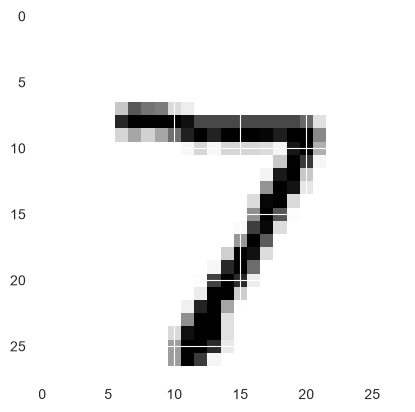

In [201]:
image_array=np.asarray(all_values[1:],dtype='float').reshape(28,28)
plt.imshow(image_array,interpolation='none',cmap='Greys')

In [202]:
np.set_printoptions(suppress=True, precision=6)
print(nn.predict((np.asarray(all_values[1:],dtype='float')/255*0.99)+0.01))

[[0.017316]
 [0.00449 ]
 [0.01759 ]
 [0.010136]
 [0.008699]
 [0.006756]
 [0.012089]
 [0.992269]
 [0.005334]
 [0.004345]]


In [203]:
#test the neural network

score_card=[]
for record in testing_data_list:
    all_values=record.split(',')
    correct_label=int(all_values[0])
    print("correct number",correct_label)
    inputs=(np.asarray(all_values[1:],dtype='float')/255*0.99)+0.01
    outputs=nn.predict(inputs)
    predicted_label=np.argmax(outputs)
    print("predicted number",predicted_label)
    if correct_label==predicted_label:
        score_card.append(1)
    else:
        score_card.append(0)
        pass
pass
print(score_card)


correct number 7
predicted number 7
correct number 2
predicted number 2
correct number 1
predicted number 1
correct number 0
predicted number 0
correct number 4
predicted number 4
correct number 1
predicted number 1
correct number 4
predicted number 4
correct number 9
predicted number 9
correct number 5
predicted number 5
correct number 9
predicted number 9
correct number 0
predicted number 0
correct number 6
predicted number 6
correct number 9
predicted number 9
correct number 0
predicted number 0
correct number 1
predicted number 1
correct number 5
predicted number 5
correct number 9
predicted number 9
correct number 7
predicted number 7
correct number 3
predicted number 3
correct number 4
predicted number 4
correct number 9
predicted number 9
correct number 6
predicted number 6
correct number 6
predicted number 6
correct number 5
predicted number 5
correct number 4
predicted number 4
correct number 0
predicted number 0
correct number 7
predicted number 7
correct number 4
predicted n

In [204]:
scorecard_array=np.asarray(score_card,dtype='float')

In [205]:
print('performance of the network=',scorecard_array.sum()/scorecard_array.size)

performance of the network= 0.9674


In [3]:
import imageio.v2 as imageio
from PIL import Image

In [5]:
image_path = r"C:\Users\User\Downloads\nn_pic.jpg"

In [6]:
img = Image.open(image_path)

In [7]:
img_gray = img.convert("L")

In [8]:
img_gray.show()